# EDA 03 · Analiza Zbioru SPRSound

<div style="border-left: 4px solid #2b6cb0; padding: 12px 16px; margin-bottom: 20px; border-radius: 0 4px 4px 0;">
  <strong>Praca Inżynierska:</strong> Analiza i klasyfikacja dźwięków z wykorzystaniem uczenia maszynowego <br>
  <strong>Autorzy:</strong> Norbert Gwiazda, Mateusz Ciurzyński | <strong>Data:</strong> 2026-10-19<br>
  <strong>Zbiór danych:</strong> SPRSound<br>
  <strong>Cel:</strong> Analiza eksploracyjna zbiorów danych
</div>

---

## Spis treści
- [1. Kontekst i Charakterystyka Bazy Danych](#1-kontekst-i-charakterystyka-bazy-danych)
---

## 1. Kontekst i Charakterystyka Bazy Danych

Zbiór *SPRSound (SJTU Paediatric Respiratory Sound Database)* zawiera próbki dźwięków oddechowych, zebrane i opracowane wspólnie przez instytucje z Chin:
- **Uniwersytet Jiao Tong w Szanghaju (SJTU)** — wiodąca rola badawcza i inżynieryjna.
- **Szanghajskie Dziecięce Centrum Medyczne (SCMC)** — nagrania pochodzą bezpośrednio z badań klinicznych pacjentów pediatrycznych przeprowadzonych w tej placówce.

Baza danych zawiera $6567$ nagrania audio, w których wyodrębniono i połączono z adnotacjami ponad $56977$ cykli oddechowych (zdarzeń akustycznych). Dane zebrano od $860$ pacjentów pediatrycznych. Każdemu nagraniu `.wav` towarzyszy dedykowany plik adnotacji w formacie `.json`. Pliki te definiują parametry nagrania (identyfikator pacjenta, pozycję osłuchu, wiek, płeć) oraz zawierają dokładne przedziały czasowe i etykiety dla każdego zdarzenia oddechowego -- klasy patologiczne: *Wheeze, Fine Crackle, Coarse Crackle, Wheeze+Crackle, Rhonchi, Stridor* oraz klasa *Normal*.

Lokalizacje osłuchu:
- Left Posterior (P1) - Lewy tył
- Left Lateral (P2) - Lewy boczny
- Right Posterior (P3) - Prawy tył
- Right Lateral (P4) - Prawy boczny
- P5-P8 ??? TODO

Sprzęt użyty do badania to Yunting model II Stethoscopes


## 2. Środowisko i Import Bibliotek

In [8]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
%config InlineBackend.close_figures = True


import os
import warnings
from pathlib import Path

import librosa
import matplotlib.gridspec as gridspec

# Wizualizacja danych
import matplotlib.pyplot as plt

# Przetwarzanie i analiza numeryczna
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import scipy.stats as stats
import seaborn as sns
import statsmodels.api as sm
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from pyfonts import load_google_font
from pypalettes import load_cmap, load_palette
from scipy.signal import find_peaks
import json


# Wyciszenie zbędnych ostrzeżeń
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

# Wczytanie czionek i palet kolorów
dark_two = load_palette("Dark2")
regular = load_google_font("Roboto", weight=400)
medium = load_google_font("Roboto", weight=500)
bold = load_google_font("Roboto", weight=700)
heavy = load_google_font("Roboto", weight=800)

# Ustawienie motywu
sns.set_theme(style="whitegrid")

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42


## 3. Wczytanie danych

W pierwszej kolejności przyjrzymy się zawartości folderu zbioru danych

In [9]:
DATA_PATH = Path('../data/SPRSound') 
CACHE_DIR = '.cache'
CACHE_FILE = os.path.join(CACHE_DIR, 'sprsound_features.parquet')

os.makedirs(CACHE_DIR, exist_ok=True)

if os.path.exists(CACHE_FILE):
    print(f"Wczytywanie pamięci podręcznej z {CACHE_FILE}")
    table = pq.read_table(CACHE_FILE)
    df = table.to_pandas()

    # 1. Mapowanie wszystkich plików .wav (nazwa pliku -> pełna ścieżka)
wav_paths = { f.stem : f for f in list(DATA_PATH.rglob("*.wav"))}

print(f"Wszystkich nagrań: {len(wav_paths)}")
print("Pierwsze 5 nagrań:")
for f in list(wav_paths.keys())[:5]:
    print(f"  - {f}")

Wszystkich nagrań: 6567
Pierwsze 5 nagrań:
  - 65097128_5.6_1_p1_2242
  - 65097128_5.6_1_p1_2332
  - 65097128_5.6_1_p1_2377
  - 65097128_5.6_1_p1_2430
  - 65097128_5.6_1_p1_2467


Przetworzenie plików audio może być problematyczne, dlatego załadujemy metadane do ramki pandas, a do samych plików audio umieścimy wskaźnik.

In [10]:
if not os.path.exists(CACHE_FILE):
    annotations = []
    
    for json_file in DATA_PATH.rglob("*.json"):
        filename = json_file.stem
            
        with open(json_file, 'r', encoding='utf-8') as f:
            try:
                data = json.load(f)

                events = data['event_annotation'] 
                
                for event in events:
                    event_type = event['type'].lower()
                    
                    annotations.append({
                        "start": float(event['start']),
                        "end": float(event['end']),
                        "event_type": event_type,
                        "filename": filename,
                        "wav_path": wav_paths[filename],
                        "patient_id": filename.split('_')[0],
                        'patient_age': int(float(filename.split('_')[1])),
                        'patient_gender': {'0': 'Male', '1': 'Female'}[filename.split('_')[2]],
                        'chest_location': filename.split('_')[3]
                    })
            except Exception as e:
                print(f"Błąd parsowania pliku {json_file.name}: {e}")
    df = pd.DataFrame(annotations)
    print(f"Załadowano {len(df)} zdarzeń z {df['filename'].nunique()} nagrań.")
df.head()

Załadowano 56977 zdarzeń z 6337 nagrań.


,start,end,event_type,filename,wav_path,patient_id,patient_age,patient_gender,chest_location
0,1468.0,2725.0,normal,65097128_5.6_1_p1_2242,..\data\SPRSound\Detection\train_detection_wav...,65097128,5,Female,p1
1,3181.0,4357.0,normal,65097128_5.6_1_p1_2242,..\data\SPRSound\Detection\train_detection_wav...,65097128,5,Female,p1
2,4725.0,5945.0,normal,65097128_5.6_1_p1_2242,..\data\SPRSound\Detection\train_detection_wav...,65097128,5,Female,p1
3,6166.0,7383.0,normal,65097128_5.6_1_p1_2242,..\data\SPRSound\Detection\train_detection_wav...,65097128,5,Female,p1
4,7693.0,9173.0,normal,65097128_5.6_1_p1_2242,..\data\SPRSound\Detection\train_detection_wav...,65097128,5,Female,p1


W ramach wstępnej analizy załadowane zostanie dodatkowo kilka cech wyciągniętych z plików audio.

In [11]:
if not os.path.exists(CACHE_FILE):
    rms_dict = {}
    zcr_dict = {}
    spectral_centroid_dict = {}
    spectral_flatness_dict = {}
    spectral_rolloff_dict = {}
    spectral_bandwidth_dict = {}
    crest_factor = {}

    for wav_path in df['wav_path'].unique():
        y, sr = librosa.load(wav_path , sr=None)
        rms = np.mean(librosa.feature.rms(y=y))
        zcr_dict[wav_path] = np.mean(librosa.feature.zero_crossing_rate(y=y))
        rms_dict[wav_path] = rms

        crest_factor[wav_path]  = np.max(np.abs(y)) / (rms+ 1e-8)

        spectral_centroid_dict[wav_path] = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
        spectral_bandwidth_dict[wav_path] = np.mean(librosa.feature.spectral_bandwidth(y=y, sr=sr))
        spectral_rolloff_dict[wav_path] = np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85))
        spectral_flatness_dict[wav_path] = np.mean(librosa.feature.spectral_flatness(y=y))


    df['audio_rms'] = df['wav_path'].map(rms_dict)
    df['audio_zcr'] = df['wav_path'].map(zcr_dict)
    df['crest_factor'] = df['wav_path'].map(crest_factor)

    df['spectral_centroid'] = df['wav_path'].map(spectral_centroid_dict)
    df['spectral_bandwidth'] = df['wav_path'].map(spectral_bandwidth_dict)
    df['spectral_rolloff'] = df['wav_path'].map(spectral_rolloff_dict)
    df['spectral_flatness'] = df['wav_path'].map(spectral_flatness_dict)

    table = pa.Table.from_pandas(df.drop(columns=['wav_path']))
    pq.write_table(table, CACHE_FILE)
    print(f"Zapisano dane do buforu {CACHE_FILE}")

Zapisano dane do buforu .cache\sprsound_features.parquet


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56977 entries, 0 to 56976
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start               56977 non-null  float64
 1   end                 56977 non-null  float64
 2   event_type          56977 non-null  str    
 3   filename            56977 non-null  str    
 4   wav_path            56977 non-null  object 
 5   patient_id          56977 non-null  str    
 6   patient_age         56977 non-null  int64  
 7   patient_gender      56977 non-null  str    
 8   chest_location      56977 non-null  str    
 9   audio_rms           56977 non-null  float32
 10  audio_zcr           56977 non-null  float64
 11  crest_factor        56977 non-null  float32
 12  spectral_centroid   56977 non-null  float64
 13  spectral_bandwidth  56977 non-null  float64
 14  spectral_rolloff    56977 non-null  float64
 15  spectral_flatness   56977 non-null  float32
dtypes: float32(3), 

In [13]:
df.head()

,start,end,event_type,filename,wav_path,patient_id,patient_age,patient_gender,chest_location,audio_rms,audio_zcr,crest_factor,spectral_centroid,spectral_bandwidth,spectral_rolloff,spectral_flatness
0,1468.0,2725.0,normal,65097128_5.6_1_p1_2242,..\data\SPRSound\Detection\train_detection_wav...,65097128,5,Female,p1,0.00282,0.041162,84.901863,223.650734,307.274302,313.79668,0.000098
1,3181.0,4357.0,normal,65097128_5.6_1_p1_2242,..\data\SPRSound\Detection\train_detection_wav...,65097128,5,Female,p1,0.00282,0.041162,84.901863,223.650734,307.274302,313.79668,0.000098
2,4725.0,5945.0,normal,65097128_5.6_1_p1_2242,..\data\SPRSound\Detection\train_detection_wav...,65097128,5,Female,p1,0.00282,0.041162,84.901863,223.650734,307.274302,313.79668,0.000098
3,6166.0,7383.0,normal,65097128_5.6_1_p1_2242,..\data\SPRSound\Detection\train_detection_wav...,65097128,5,Female,p1,0.00282,0.041162,84.901863,223.650734,307.274302,313.79668,0.000098
4,7693.0,9173.0,normal,65097128_5.6_1_p1_2242,..\data\SPRSound\Detection\train_detection_wav...,65097128,5,Female,p1,0.00282,0.041162,84.901863,223.650734,307.274302,313.79668,0.000098


In [14]:
print(list(df['event_type'].unique()))

['normal', 'fine crackle', 'wheeze', 'coarse crackle', 'wheeze+crackle', 'rhonchi', 'stridor']


## 4. Analiza jednowymiarowa

Przygotowany zbiór danych poddano szczegółowej analizie jednowymiarowej. W pierwszej kolejności omówiono poszczególne zmienne kategoryczne, zwieńczając każdą z podsekcji zbiorczym podsumowaniem wyników. Następnie analogicznej ocenie poddano cechy binarne, skupiając się na jednostkowej charakterystyce każdej z nich bez uwzględniania zależności międzyzmiennych.

---

### 4.1 Miejsca odsłuchów


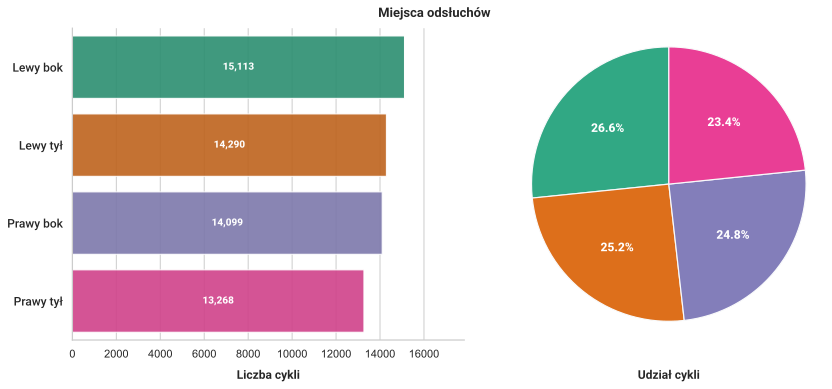

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=125, constrained_layout=True)

# Chcemy, aby kolory były przypisane do kategorii
counts = df[df.isin(['p1', 'p2', 'p3', 'p4'])]['chest_location'].value_counts().sort_values(ascending=False)
color_dict = dict(zip(counts.index, dark_two[:4], strict=True))
labels_map = {
    "p1": "Lewy tył",
    "p2": "Lewy bok",
    "p3": "Prawy tył",
    "p4": "Prawy bok",

}

# Wykres słupkowy do oceny ilości
sns.barplot(
    y=counts.index,
    x=counts.values,
    hue=counts.index,
    palette=color_dict,
    legend=False,
    ax=ax1,
    alpha=0.9
)

# Polskie etykiety
ax1.set_yticks(range(len(labels_map)))
ax1.set_yticklabels([labels_map[label] for label in counts.index], fontsize=10.5, font=medium)

# Wartości liczbowe przy słupkach
for container in ax1.containers:
    labels = [f"{v.get_width():,.0f}" for v in container]
    ax1.bar_label(container, labels=labels, size=10, font=heavy, color="white", label_type="center")

# Poprawione etykiety
ax1.set_ylabel("")
ax1.set_xlabel('Liczba cykli', labelpad=10, font=bold)
ax1.set_xlim(0, df['chest_location'].value_counts().max() * 1.18)

# Wykres kołowy do prezentacji udziału w całości
wedges, texts, autotexts = ax2.pie(
    counts,
    labels=None,
    autopct='%1.1f%%',
    startangle=90,
    colors=[color_dict[cat] for cat in counts.index],
    wedgeprops={"alpha":0.9, "linewidth": 1.2, "edgecolor": "#f8f9fa"},
    radius=1.1
)

# Korekta graficzna wartości procentowych
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_size(10)
    autotext.set_font(heavy)

ax2.set_xlabel('Udział cykli', labelpad=10, font=bold)

fig.align_xlabels([ax1,ax2])
fig.suptitle('Miejsca odsłuchów ', size=13, font=bold, y=1.05)

sns.despine(top=True, right=True)
plt.show()

In [18]:
percentages = (counts / len(df)) * 100
pd.DataFrame({'Miejsca odsłuchów': [labels_map[label] for label in counts.index], 'Liczebność': [f"{val:,.0f}" for val in counts], 'Udział (%)': [f"{val:.2f}%" for val in percentages]})

,Miejsca odsłuchów,Liczebność,Udział (%)
0,Lewy boczny,"15,113",26.52%
1,Lewy tył,"14,290",25.08%
2,Prawy boczny,"14,099",24.75%
3,Prawy tył,"13,268",23.29%
4,P8,131,0.23%
5,P7,36,0.06%
6,P5,30,0.05%
7,P6,10,0.02%


In [ ]:
df = df[df.isin(['p1', 'p2', 'p3', 'p4'])]

Rozkład miejsc odsłuchow cechuje się znacznym niezbalansowaniem kategorii, które objawia się znaczącym brakiem reprezentacji dla klas P5-P8. Wynika to z faktu że klasy te zostały dodane w kolejnych edycjach konkursu a i wtedy nie występowały często. Z tego powodu rekordy z tych klas zostaną pominięte z dalszej analizy. Pozostałe klasy cechują się dobrym zbalansowaniem.

---

### 4.2 Anomalie oddechowe

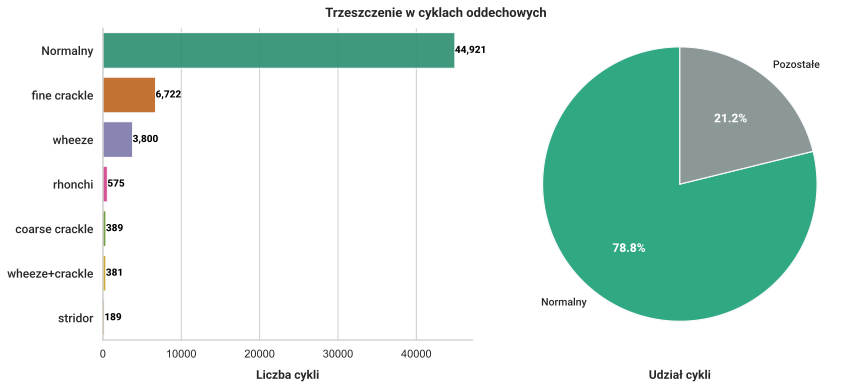

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=125, constrained_layout=True)

# Chcemy, aby kolory były przypisane do kategorii
counts = df['event_type'].value_counts().sort_values(ascending=False)
counts.index = counts.index.astype(str)

color_dict = dict(zip(counts.index, dark_two[:7], strict=True))
labels_map = {
    'normal': "Normalny",
    'fine crackle': "fine crackle",
    'wheeze': 'wheeze',
    'coarse crackle': 'coarse crackle',
    'wheeze+crackle': 'wheeze+crackle',
    'rhonchi': 'rhonchi',
    'stridor': 'stridor'
}

# --- Wykres słupkowy (bez zmian) ---
sns.barplot(
    y=counts.index,
    x=counts.values,
    hue=counts.index,
    palette=color_dict,
    legend=False,
    ax=ax1,
    alpha=0.9
)

# Polskie etykiety
ax1.set_yticks(range(len(labels_map)))
ax1.set_yticklabels([labels_map[label] for label in counts.index], fontsize=10.5, font=medium)

# Wartości liczbowe przy słupkach
for container in ax1.containers:
    labels = [f"{v.get_width():,.0f}" for v in container]
    ax1.bar_label(container, labels=labels, size=10, font=heavy, color="black", label_type="edge")

# Poprawione etykiety
ax1.set_ylabel("")
ax1.set_xlabel('Liczba cykli', labelpad=10, font=bold)


normal_count = counts.get('normal', 0)
abnormal_count = counts[counts.index != 'normal'].sum()

pie_counts = [normal_count, abnormal_count]
pie_labels = ['Normalny', 'Pozostałe']
pie_colors = [color_dict.get('normal', '#2ecc71'), '#7f8c8d'] 

wedges, texts, autotexts = ax2.pie(
    pie_counts,
    labels=pie_labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=pie_colors,
    wedgeprops={"alpha":0.9, "linewidth": 1.2, "edgecolor": "#f8f9fa"},
    radius=1.1
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_size(10)
    autotext.set_font(heavy)

for text in texts:
    text.set_font(medium)
    text.set_size(10.5)

ax2.set_xlabel('Udział cykli', labelpad=10, font=bold)

fig.align_xlabels([ax1,ax2])
fig.suptitle('Trzeszczenie w cyklach oddechowych', size=13, font=bold, y=1.05)

sns.despine(top=True, right=True)
plt.show()

In [34]:
percentages = (counts / len(df)) * 100
pd.DataFrame({'Miejsca odsłuchów': [labels_map[label] for label in counts.index], 'Liczebność': [f"{val:,.0f}" for val in counts], 'Udział (%)': [f"{val:.2f}%" for val in percentages]})

,Miejsca odsłuchów,Liczebność,Udział (%)
0,Normalny,"44,921",78.84%
1,fine crackle,"6,722",11.80%
2,wheeze,"3,800",6.67%
3,rhonchi,575,1.01%
4,coarse crackle,389,0.68%
5,wheeze+crackle,381,0.67%
6,stridor,189,0.33%
